# AT&T Spam Detector : détecter les SMS indésirables par apprentissage profond

*Certification RNCP35288 (Concepteur Développeur en Science des Données), bloc 4 : analyse
prédictive de données non structurées par l'intelligence artificielle.*

**Contexte (énoncé du projet)** : les abonnés d'AT&T reçoivent sans cesse des SMS indésirables
(*spam*). AT&T les signalait à la main et veut un détecteur automatique, fondé **uniquement sur
le contenu du message**. Livrable : un notebook qui prétraite les SMS, entraîne un ou plusieurs
modèles d'apprentissage profond et **énonce clairement la performance atteinte**. Conseils de
l'énoncé : commencer simple ; essayer le *transfer learning* (peu de données disponibles).

**Données** : `spam.csv` (5 572 SMS en anglais étiquetés `ham` ou `spam`), fourni avec
l'énoncé du projet, non redistribué ici (voir le README du bloc).

**Plan** : 1. Chargement et réparation des données ; 2. Préparation : normalisation,
découpage par groupes sans quasi-doublon (Jaccard ≥ 0,8) entre apprentissage et test, tenseurs et augmentation (C4.1) ; 3. Référence non profonde ; 4. Réseaux
construits : convolutif et récurrent (C4.2) ; 5. Réseau pré-entraîné DistilBERT (C4.3) ;
6. Génération de SMS par réseaux adverses (C4.4) ; 7. Évaluation finale sur le jeu de test
(C4.5) ; 8. Signaux détectés ; 9. Lien avec l'analyse de sentiment ; 10. RGPD ; 11. Limites ;
12. Sauvegarde.

| Compétence ou critère du référentiel (bloc 4) | Section |
|---|---|
| C4.1 Traiter des données non structurées en matrices ; création de tenseurs, augmentation | 2, 6.3 |
| C4.2 Réseaux de neurones adaptés (convolutifs, récursifs) ; pertinence du type de réseau | 4 |
| Fonction de coût (entropie croisée) et critères d'évaluation | 4, 6, 7 |
| C4.3 Configurer un réseau pré-entraîné profond (transfer learning) | 5 |
| C4.4 Créer des données non structurées avec des réseaux adverses ; qualité des données | 6 |
| C4.5 Indicateurs sur entraînement et validation ; tests de généralisation sur le test | 4, 5, 7 |
| Clarté de la détection des signaux | 8 |
| Propreté du code (PEP 8) | tout le notebook |

## Fiche de documentation vivante

### CHOIX

- **Retenu** : un notebook qui raconte la démarche (cellules Markdown) et un paquet `att_spam/` qui
  porte les fonctions, extraites pour être testées : `att_spam/donnees.py` (réparation,
  normalisation, quasi-doublons, découpage, tenseurs, augmentation), `att_spam/reseaux.py`
  (perte pondérée, TextCNN, BiGRU, boucle d'apprentissage), `att_spam/bert.py` (DistilBERT),
  `att_spam/gan.py` (GAN et mesures de qualité), `att_spam/evaluation.py` (seuil, bootstrap, Wilson,
  McNemar, ablation).
- **Retenu** : un découpage par groupes de quasi-doublons (Jaccard ≥ 0,8) : à ce seuil, aucun SMS
  du test n'est quasi identique à un SMS de l'apprentissage. Des ressemblances plus faibles
  subsistent (section 2.2) : le notebook les mesure et ne prétend pas à l'absence de fuite.
- **Retenu** : le modèle et le seuil se choisissent sur la validation ; le test ne sert qu'une fois.
- **Écarté** : un découpage au hasard (une campagne de spam tomberait des deux côtés) ;
  l'exactitude comme indicateur (87 % en répondant toujours « légitime ») ; relancer DistilBERT
  sur sept plis (environ 9 minutes par ajustement) ; déposer les poids ajustés de DistilBERT
  (268 Mo).

### OÙ

- Entrée : `spam.csv`, dans le dossier du notebook. Sorties : `modeles/textcnn.pt`,
  `modeles/bigru.pt`, `modeles/vocabulaire.pt`, `modeles/resultats_test.csv` ;
  `modeles/distilbert_ajuste` est régénéré par la dernière cellule mais n'est pas déposé.
- Paquet `att_spam/` appelé par ce notebook ; tests dans `tests/` ; versions épinglées dans
  `requirements.txt`.

### COMMENT

- Exécuter les cellules dans l'ordre, depuis le dossier du notebook : environ 28 minutes sur
  processeur, dont environ 9 minutes pour l'ajustement de DistilBERT. Graine 42 et algorithmes
  déterministes : deux exécutions donnent les mêmes sorties chiffrées (hors durées).
- Tests qui le prouvent : `tests/test_donnees.py`, `tests/test_reseaux.py`, `tests/test_bert.py`,
  `tests/test_gan.py`, `tests/test_evaluation.py` (fonctions du paquet, y compris les entrées
  refusées) ; `tests/test_chiffres_reels.py` (chiffres de la préparation sur le vrai `spam.csv`) ;
  `tests/test_notebook.py` (exécution du notebook avec nbclient et contrôle de ses chiffres).

### POURQUOI

- Énoncé du projet AT&T Spam Detector (consigne et livrable attendu) : énoncé du projet, non
  redistribué.
  Compétences C4.1 à C4.5 : référentiel de compétences RNCP35288, bloc 4.
- Les chiffres cités dans les cellules Markdown sont rejoués par `tests/test_notebook.py`.
- Le seuil de similarité 0,8 est un choix de conception : source : inconnue (aucune étude citée).

### JOURNALISATION

- Aucune journalisation applicative (pas de `logging`) : les cellules affichent leurs résultats
  avec `print` ; la progression de chaque entraînement (une ligne par époque) est affichée par
  les fonctions du paquet `att_spam/`.
- `att_spam/bert.py` règle `transformers` et `huggingface_hub` sur le niveau ERROR, coupe leurs
  barres de progression et masque l'avertissement « requêtes non authentifiées ».
  `torch.use_deterministic_algorithms(True, warn_only=True)` : une opération non déterministe
  émet un avertissement sans interrompre le calcul.
- Fichiers écrits : section 12 (`modeles/`).

In [1]:
import os
import random
import time
import warnings
from collections.abc import Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from att_spam.donnees import (
    Augmenteur,
    Encodeur,
    charger_sms,
    decouper_mots,
    decouper_par_groupes,
    grouper_quasi_doublons,
    matrice_presence,
    normaliser,
    similarites,
)
from att_spam.evaluation import (
    Reels,
    ablation,
    entrainer_reference,
    erreurs_du_modele,
    evaluer,
    f1,
    f1_reference_par_pli,
    mcnemar,
    meilleure_epoque,
    performance,
    probabilites_reference,
    tirages_bootstrap,
)
from att_spam.gan import (
    Discriminateur,
    Generateur,
    VocabulaireGAN,
    compter_mots,
    entrainer_adverse,
    forme_phrases,
    generer,
    melanger,
    mesurer,
    pre_entrainer,
    quadrigrammes,
    tirer_independamment,
)
from att_spam.reseaux import (
    BiGRU,
    Historique,
    TextCNN,
    creer_perte,
    entrainer,
    poids_spam,
    probabilites,
)

# Avertissement d'affichage de tqdm (barres de progression sans widget Jupyter) : sans objet
# ici, on le masque avant que transformers (importé en section 5) ne l'utilise ; de même pour
# les barres de progression de téléchargement.
warnings.filterwarnings("ignore", message="IProgress not found")
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

# Reproductibilité : même graine pour Python, NumPy et PyTorch ; algorithmes déterministes.
GRAINE = 42
random.seed(GRAINE)
np.random.seed(GRAINE)
torch.manual_seed(GRAINE)
torch.use_deterministic_algorithms(True, warn_only=True)
# Calcul sur processeur uniquement (pas de carte graphique) : on utilise tous les cœurs.
torch.set_num_threads(os.cpu_count() or 1)
print("PyTorch", torch.__version__, "| cœurs utilisés :", torch.get_num_threads())

PyTorch 2.14.1+cpu | cœurs utilisés : 24


## 1. Chargement et réparation des données

Le fichier compte cinq colonnes : `v1` (étiquette), `v2` (texte) et trois colonnes « Unnamed »
presque vides. Ce ne sont pas des variables : ce sont des **morceaux de SMS** coupés aux
virgules lors de l'export du fichier. On reconstitue donc le texte complet en recollant ces
morceaux avec une virgule. Ensuite, on retire les **doublons** de texte *avant* tout découpage :
un même SMS présent à la fois dans l'apprentissage et dans le test gonflerait artificiellement
la performance mesurée (fuite de données). Les doublons *approximatifs* sont traités en 2.2.

In [2]:
chargement = charger_sms("spam.csv")
donnees = chargement.donnees

print(
    f"SMS lus : {chargement.nb_lus} ; "
    f"SMS coupés aux virgules et réparés : {chargement.nb_coupes}"
)
print(f"Doublons de texte retirés : {chargement.nb_doublons} ; SMS uniques : {len(donnees)}")
print(donnees["etiquette"].value_counts().to_string())
print(f"Part de spam : {donnees['cible'].mean():.1%}")

SMS lus : 5572 ; SMS coupés aux virgules et réparés : 50
Doublons de texte retirés : 403 ; SMS uniques : 5169
etiquette
ham     4516
spam     653
Part de spam : 12.6%


            count   mean   std   min    25%    50%    75%    max
etiquette                                                       
ham        4516.0   71.1  56.7   2.0   34.0   53.0   92.0  910.0
spam        653.0  138.2  29.9  13.0  132.0  149.0  157.0  224.0


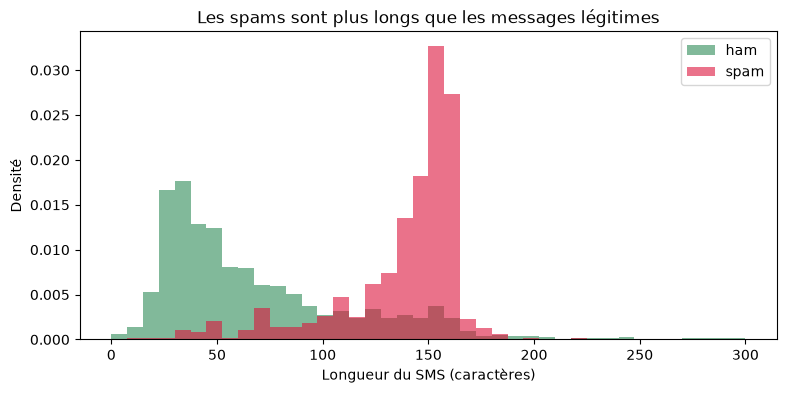

In [3]:
donnees["nb_caracteres"] = donnees["texte"].str.len()
print(donnees.groupby("etiquette")["nb_caracteres"].describe().round(1))
fig, ax = plt.subplots(figsize=(9, 4))
for etiquette, couleur in [("ham", "seagreen"), ("spam", "crimson")]:
    ax.hist(
        donnees.loc[donnees["etiquette"] == etiquette, "nb_caracteres"],
        bins=40,
        range=(0, 300),
        alpha=0.6,
        label=etiquette,
        color=couleur,
        density=True,
    )
ax.set_title("Les spams sont plus longs que les messages légitimes")
ax.set_xlabel("Longueur du SMS (caractères)")
ax.set_ylabel("Densité")
ax.legend()
plt.show()

> **Interprétation** : 50 SMS coupés aux virgules ont été réparés et 403 doublons retirés :
> il reste 5 169 messages uniques, dont 653 spams (12,6 %). Les classes sont déséquilibrées :
> un modèle qui dirait toujours « légitime » aurait 87 % d'exactitude sans rien détecter, d'où
> le choix du F1, de la précision et du rappel. Les spams sont nettement plus longs (médiane de
> 149 caractères contre 53) et concentrés entre 132 et 157 caractères, près de la limite de 160
> caractères d'un SMS : leurs auteurs remplissent le message. La longueur est donc un signal,
> mais insuffisant à elle seule (certains messages légitimes dépassent 900 caractères).

## 2. Préparation des données : du texte aux tenseurs (C4.1)

### 2.1 Normalisation : rendre visibles les signaux typiques du spam

Les spams contiennent des numéros surtaxés, des montants et des liens. Leur valeur exacte ne
compte pas (chaque numéro est unique et n'apparaîtrait qu'une fois dans le vocabulaire) ; leur
**présence**, si. On les remplace par des jetons génériques : `<url>`, `<argent>`, `<tel>`
(suite d'au moins 5 chiffres) et `<nombre>`. Le texte est aussi mis en minuscules. Les mots qui
mêlent chiffres et lettres (« 2nd », « 4u », « txt2win ») sont gardés entiers : ce sont des
marqueurs d'écriture SMS, souvent caractéristiques du spam. Cette normalisation sert à **tous**
les modèles, DistilBERT compris : elle retire aussi des numéros de téléphone, une donnée
personnelle (section 10). Les motifs (expressions régulières) sont définis dans
`att_spam/donnees.py` (`MOTIF_URL`, `MOTIF_ARGENT`, `MOTIF_TEL`, `MOTIF_NOMBRE`), où ils
sont testés (`tests/test_donnees.py`).

In [4]:
# Les motifs (URL, montant, numéro, nombre) et les fonctions normaliser() et decouper_mots()
# sont dans att_spam/donnees.py, où ils sont testés.
donnees["texte_normalise"] = donnees["texte"].map(normaliser)
donnees["mots"] = donnees["texte_normalise"].map(decouper_mots)
exemple = donnees.loc[donnees["cible"] == 1].iloc[0]
print("Exemple :", exemple["texte"])
print("     →   ", exemple["mots"])

Exemple : <SMS du corpus, non reproduit>
     →    <découpage en mots, non reproduit>


### 2.2 Découpage 70 / 15 / 15 par groupes : sans quasi-doublon (Jaccard ≥ 0,8) entre apprentissage et test

- **apprentissage** (environ 70 %) : les modèles y apprennent ;
- **validation** (environ 15 %) : choix des époques (arrêt précoce), du seuil de décision et du
  modèle retenu ;
- **test** (environ 15 %) : utilisé **une seule fois**, à la fin, pour mesurer la
  généralisation.

**Piège** : retirer les doublons exacts ne suffit pas. Une même campagne de spam est envoyée
en de nombreuses variantes qui ne diffèrent que par le numéro, le montant ou un mot. Si une
variante est en apprentissage et une autre en test, le modèle « reconnaît » la campagne au lieu
de détecter un spam nouveau, et la mesure risque d'être trop belle. On regroupe donc les
SMS **quasi identiques** (similarité de Jaccard d'au moins 0,8 entre leurs ensembles de mots
normalisés, par transitivité) et **chaque groupe va tout entier dans un seul jeu**. Le
découpage reste **stratifié** (même part de spam dans chaque jeu, environ 12,6 %) grâce à
`StratifiedGroupKFold` : 7 plis de taille égale, un pour le test, un pour la validation, cinq
pour l'apprentissage.

In [5]:
# Ensemble des mots de chaque SMS sous forme de matrice creuse binaire (une ligne par SMS, une
# colonne par mot). Le produit X·Xᵀ donne le nombre de mots communs à chaque paire de SMS, d'où
# la similarité de Jaccard = communs / (|A| + |B| − communs), calculée sans double boucle.
# Graphe : une arête entre deux SMS distincts quasi identiques (Jaccard ≥ 0,8) ; un groupe = une
# composante connexe (si A ressemble à B et B à C, les trois vont ensemble).
presence_mots = matrice_presence(donnees["mots"].tolist())
nb_groupes, etiquettes_groupes = grouper_quasi_doublons(presence_mots)
donnees["groupe"] = etiquettes_groupes
taille_groupe = donnees["groupe"].map(donnees["groupe"].value_counts())
print(
    f"Groupes : {nb_groupes} pour {len(donnees)} SMS ; plus grand groupe : {taille_groupe.max()}"
)
print(f"SMS ayant au moins un quasi-doublon : {(taille_groupe >= 2).sum()}")
print(
    "Spams ayant au moins un quasi-doublon :",
    f"{((taille_groupe >= 2) & (donnees['cible'] == 1)).sum()} sur {donnees['cible'].sum()}",
)
print(
    "Groupes mêlant spam et légitime (étiquettes contradictoires) :",
    int((donnees.groupby("groupe")["cible"].nunique() > 1).sum()),
)

Groupes : 4969 pour 5169 SMS ; plus grand groupe : 12
SMS ayant au moins un quasi-doublon : 330
Spams ayant au moins un quasi-doublon : 252 sur 653
Groupes mêlant spam et légitime (étiquettes contradictoires) : 0


In [6]:
decoupage = decouper_par_groupes(donnees, GRAINE)
apprentissage, validation, test = decoupage.apprentissage, decoupage.validation, decoupage.test
plis = decoupage.plis
for nom, jeu in [("apprentissage", apprentissage), ("validation", validation), ("test", test)]:
    print(
        f"{nom:<13} : {len(jeu):>4} SMS, dont {jeu['cible'].sum():>3} spams "
        f"({jeu['cible'].mean():.1%})"
    )

# Contrôles : aucun groupe partagé, et plus grande similarité restante entre un SMS de test et
# un SMS d'apprentissage (elle doit être inférieure au seuil, par construction).
jaccard_test = similarites(presence_mots, test.index.to_numpy(), apprentissage.index.to_numpy())
print(
    "Groupes partagés entre apprentissage et validation ou test :",
    len(decoupage.groupes_partages()),
)
print(f"Similarité maximale entre un SMS de test et l'apprentissage : {jaccard_test.max():.3f}")
# Le seuil de 0,8 est un choix : on affiche ce qui reste sous ce seuil, pour les spams de test
# (combien ressemblent encore, à des degrés moindres, à un SMS d'apprentissage).
similarite_spams_test = jaccard_test[test["cible"].to_numpy() == 1].max(axis=1)
for seuil_affiche in (0.5, 0.6, 0.7):
    print(
        f"Spams de test dont le plus proche SMS d'apprentissage a une similarité ≥ "
        f"{seuil_affiche} : {(similarite_spams_test >= seuil_affiche).sum()} sur "
        f"{len(similarite_spams_test)}"
    )

apprentissage : 3691 SMS, dont 466 spams (12.6%)
validation    :  739 SMS, dont  94 spams (12.7%)
test          :  739 SMS, dont  93 spams (12.6%)
Groupes partagés entre apprentissage et validation ou test : 0
Similarité maximale entre un SMS de test et l'apprentissage : 0.786
Spams de test dont le plus proche SMS d'apprentissage a une similarité ≥ 0.5 : 34 sur 93
Spams de test dont le plus proche SMS d'apprentissage a une similarité ≥ 0.6 : 17 sur 93
Spams de test dont le plus proche SMS d'apprentissage a une similarité ≥ 0.7 : 10 sur 93


In [7]:
# Ces jetons sont-ils des signaux ? Part des SMS de chaque classe qui en contiennent un
# (mesurée sur l'apprentissage seulement).
for jeton in ["<url>", "<argent>", "<tel>", "<nombre>"]:
    presence = apprentissage["mots"].map(lambda mots, j=jeton: j in mots)
    print(
        f"{jeton:<9} : présent dans {presence[apprentissage['cible'] == 1].mean():6.1%} des "
        f"spams et {presence[apprentissage['cible'] == 0].mean():5.1%} des messages légitimes"
    )

<url>     : présent dans  19.1% des spams et  0.3% des messages légitimes
<argent>  : présent dans  50.2% des spams et  0.2% des messages légitimes
<tel>     : présent dans  71.9% des spams et  0.0% des messages légitimes
<nombre>  : présent dans  63.9% des spams et 12.2% des messages légitimes


> **Interprétation** : 252 des 653 spams (39 %) ont au moins un quasi-doublon : les
> campagnes de spam se répètent avec de petites variantes, ce que le simple retrait des
> doublons exacts ne voyait pas. Les 5 169 SMS forment 4 969 groupes (le plus grand compte
> 12 messages) ; aucun ne mêle spam et légitime. Le découpage par groupes donne 3 691, 739 et
> 739 SMS, avec 12,6 à 12,7 % de spams dans chaque jeu ; aucun groupe n'est partagé, et le SMS
> de test le plus proche d'un SMS d'apprentissage a une similarité de 0,786, sous le seuil.
> Le seuil de 0,8 reste un choix : 34 des 93 spams de test ont encore une similarité d'au moins
> 0,5 avec un SMS d'apprentissage, 17 d'au moins 0,6 et 10 d'au moins 0,7. Le découpage écarte
> les quasi-doublons, pas toute ressemblance entre campagnes.
> Côté signaux, le jeton `<tel>` figure dans 72 % des spams d'apprentissage et dans aucun
> message légitime, `<argent>` dans 50 % contre 0,2 %, `<url>` dans 19 % contre 0,3 % : ce
> sont des signaux très forts. `<nombre>` est plus ambigu (64 % contre 12 %).

### 2.3 Vocabulaire, séquences d'indices et tenseurs

Le vocabulaire est construit **sur l'apprentissage seulement** (sinon des mots du test
influenceraient le modèle) ; un mot doit y apparaître au moins deux fois. Deux indices sont
réservés : `<pad>` = 0 (remplissage) et `<unk>` = 1 (mot inconnu). Chaque SMS devient une suite
d'indices de longueur fixe, choisie au 95ᵉ centile des longueurs pour ne tronquer que 5 % des
messages ; le jeu devient une **matrice d'entiers** (un tenseur PyTorch) de forme
(nombre de SMS, longueur).

In [8]:
# Vocabulaire et longueur fixe appris sur l'apprentissage seul (classe Encodeur de
# att_spam/donnees.py).
codeur = Encodeur.apprendre(apprentissage["mots"].tolist())
print(
    f"Taille du vocabulaire : {len(codeur.vocabulaire)} ; "
    f"longueur des séquences : {codeur.longueur}"
)

x_app, y_app = codeur.tenseurs(apprentissage)
x_val, y_val = codeur.tenseurs(validation)
x_test, y_test = codeur.tenseurs(test)
print("Tenseur d'apprentissage :", tuple(x_app.shape), x_app.dtype)
print("Première séquence :", x_app[0][:20].tolist(), "...")

Taille du vocabulaire : 2996 ; longueur des séquences : 33
Tenseur d'apprentissage : (3691, 33) torch.int64
Première séquence : [49, 482, 1, 906, 749, 658, 61, 10, 1320, 83, 119, 367, 1016, 138, 2046, 1017, 70, 60, 1, 139] ...


### 2.4 Augmentation de données

Pour que le réseau voie des variantes plus nombreuses des spams, chaque spam d'un lot
d'apprentissage a une chance sur deux d'être **modifié à la volée** : suppression aléatoire de
mots (probabilité 0,1 par mot) et permutation de deux mots voisins. Le sens reste
reconnaissable ; le réseau apprend à ne pas dépendre d'un mot ou d'une position précise.
L'augmentation **remplace** le spam dans le lot au lieu de l'ajouter : elle ne change pas la
proportion de spams (le déséquilibre est abordé par la pondération de la perte, section 4.1).
Elle ne touche **que l'apprentissage** : la validation et le test restent des messages réels.
Son effet est mesuré, plusieurs graines à l'appui, en 6.3.

In [9]:
# Le hasard de l'augmentation appartient à l'objet Augmenteur (att_spam/donnees.py) : il est
# réinitialisé par la graine à chaque entraînement.
augmenteur = Augmenteur(codeur.longueur, GRAINE)

for i in torch.nonzero(y_app == 1).flatten()[:3].tolist():
    print("original :", codeur.lire(x_app[i]))
    print("augmenté :", codeur.lire(augmenteur.augmenter(x_app[i].tolist())), "\n")

original : <SMS du corpus, non reproduit>
augmenté : <SMS du corpus, non reproduit>

original : <SMS du corpus, non reproduit>
augmenté : <SMS du corpus, non reproduit>

original : <SMS du corpus, non reproduit>
augmenté : <SMS du corpus, non reproduit>



## 3. Référence non profonde : ce qui est « déjà en place »

Avant le deep learning, une méthode classique sert de référence : sac de mots pondéré
(**TF-IDF**) et **régression logistique**. Un réseau de neurones n'a d'intérêt que s'il fait
mieux que cette référence, rapide et interprétable.

In [10]:
vectoriseur, reference = entrainer_reference(
    apprentissage["mots"], apprentissage["cible"], GRAINE
)
proba_ref_val = probabilites_reference(vectoriseur, reference, validation["mots"])
print(
    f"Référence TF-IDF + régression logistique - F1 de validation (seuil 0,5) : "
    f"{f1(validation['cible'], proba_ref_val >= 0.5):.3f}"
)

Référence TF-IDF + régression logistique - F1 de validation (seuil 0,5) : 0.947


## 4. Réseaux de neurones construits (C4.2)

### 4.1 Fonction de coût : l'entropie croisée binaire pondérée

Chaque réseau produit un score réel $z$ par SMS ; la probabilité d'être un spam est
$\hat{p} = \sigma(z) = 1 / (1 + e^{-z})$. L'**entropie croisée binaire** mesure l'écart entre
la prédiction et la vérité $y \in \{0, 1\}$ :

$$\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N} \left[ w \, y_i \log \hat{p}_i
+ (1 - y_i) \log (1 - \hat{p}_i) \right]$$

Elle pénalise fortement une prédiction sûre d'elle et fausse, et sa dérivée est simple, ce qui
la rend adaptée à la descente de gradient. Le poids $w$ = nombre de messages légitimes / nombre
de spams (environ 7) fait compter un spam raté autant, au total, que sept messages légitimes
mal classés. C'est un choix de conception, pas un gain démontré : le notebook n'entraîne aucun
réseau sans pondération pour le mesurer, et le seuil de décision, choisi sur la validation
(section 7), déplace lui aussi le compromis entre spams manqués et fausses alertes.
`BCEWithLogitsLoss` calcule cette perte directement à partir de $z$, de façon numériquement
stable.

### 4.2 Deux architectures adaptées au texte

- **TextCNN (convolutif)** : des filtres glissent sur 3, 4 et 5 mots consécutifs et détectent des
  expressions (« call now », « you have won ») où qu'elles soient dans le message ; un
  *max-pooling* garde le signal le plus fort de chaque filtre. Rapide et efficace sur des textes
  courts, où quelques expressions suffisent à décider.
- **BiGRU (récurrent)** : lit le message mot à mot, dans les deux sens, en gardant une mémoire
  du contexte ; il capte l'ordre des mots et les dépendances à distance.

Le code des deux classes, de la perte pondérée et de la boucle d'apprentissage (arrêt
précoce, copie du meilleur état) est dans `att_spam/reseaux.py`, où il est testé
(`tests/test_reseaux.py`).

In [11]:
# Les classes TextCNN et BiGRU, la perte pondérée et la boucle entrainer() (arrêt précoce,
# copie du meilleur état) sont dans att_spam/reseaux.py, où elles sont testées.
POIDS_SPAM = poids_spam(y_app)
perte = creer_perte(y_app)
print(f"Poids de la classe spam : {POIDS_SPAM:.2f}")

Poids de la classe spam : 6.92


In [12]:
debut = time.perf_counter()
torch.manual_seed(GRAINE)
cnn = TextCNN(len(codeur.vocabulaire))
historique_cnn = entrainer(
    cnn, x_app, y_app, x_val, y_val, perte, augmenteur, graine=GRAINE, nom="TextCNN"
)
duree_cnn = time.perf_counter() - debut
print(f"TextCNN entraîné en {duree_cnn:.0f} s")

debut = time.perf_counter()
torch.manual_seed(GRAINE)
gru = BiGRU(len(codeur.vocabulaire))
historique_gru = entrainer(
    gru, x_app, y_app, x_val, y_val, perte, augmenteur, graine=GRAINE, nom="BiGRU"
)
duree_gru = time.perf_counter() - debut
print(f"BiGRU entraîné en {duree_gru:.0f} s")

TextCNN époque  1 | perte app 0.332 val 0.414 | F1 app 0.852 val 0.806


TextCNN époque  2 | perte app 0.177 val 0.316 | F1 app 0.950 val 0.863


TextCNN époque  3 | perte app 0.103 val 0.259 | F1 app 0.979 val 0.888


TextCNN époque  4 | perte app 0.062 val 0.221 | F1 app 0.983 val 0.921


TextCNN époque  5 | perte app 0.040 val 0.218 | F1 app 0.994 val 0.926


...

BiGRU époque  5 | perte app 0.053 val 0.171 | F1 app 0.982 val 0.938


BiGRU époque  6 | perte app 0.036 val 0.160 | F1 app 0.986 val 0.948


BiGRU époque  7 | perte app 0.032 val 0.158 | F1 app 0.982 val 0.929


BiGRU époque  8 | perte app 0.020 val 0.166 | F1 app 0.985 val 0.924


BiGRU époque  9 | perte app 0.016 val 0.174 | F1 app 0.994 val 0.948
BiGRU arrêt précoce : pas de progrès depuis 3 époques
BiGRU entraîné en 18 s


### 4.3 Courbes d'apprentissage : sur-apprentissage ou sous-apprentissage ?

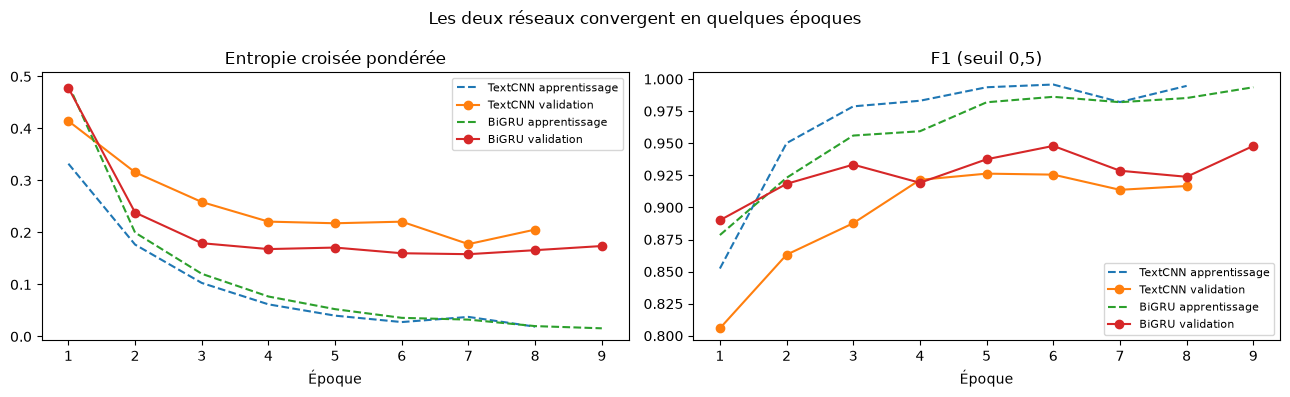

TextCNN  : meilleure époque 5 (F1 val 0.926, perte val 0.218) ; perte val minimale 0.178 à l'époque 7
BiGRU    : meilleure époque 6 (F1 val 0.948, perte val 0.160) ; perte val minimale 0.158 à l'époque 7


In [13]:
def tracer(historiques: dict[str, Historique], titre: str) -> None:
    """Courbes de perte et de F1, apprentissage contre validation, pour chaque modèle."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for nom, h in historiques.items():
        epoques = range(1, len(h["perte_val"]) + 1)
        axes[0].plot(epoques, h["perte_app"], "--", label=f"{nom} apprentissage")
        axes[0].plot(epoques, h["perte_val"], "-o", label=f"{nom} validation")
        axes[1].plot(epoques, h["f1_app"], "--", label=f"{nom} apprentissage")
        axes[1].plot(epoques, h["f1_val"], "-o", label=f"{nom} validation")
    axes[0].set_title("Entropie croisée pondérée")
    axes[1].set_title("F1 (seuil 0,5)")
    for ax in axes:
        ax.set_xlabel("Époque")
        ax.legend(fontsize=8)
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()


tracer(
    {"TextCNN": historique_cnn, "BiGRU": historique_gru},
    "Les deux réseaux convergent en quelques époques",
)
for nom, h in [("TextCNN", historique_cnn), ("BiGRU", historique_gru)]:
    k = meilleure_epoque(h)
    print(
        f"{nom:<8} : meilleure époque {k + 1} (F1 val {h['f1_val'][k]:.3f}, perte val "
        f"{h['perte_val'][k]:.3f}) ; perte val minimale {min(h['perte_val']):.3f} à l'époque "
        f"{int(np.argmin(h['perte_val'])) + 1}"
    )

> **Interprétation** : les deux réseaux apprennent vite. Le TextCNN atteint son meilleur F1
> de validation (0,926) à la 5ᵉ époque, alors que sa perte de validation baisse encore jusqu'à
> la 7ᵉ (0,178) : sur 94 spams de validation, le F1 au seuil 0,5 change d'un ou deux messages
> d'une époque à l'autre et il est plus bruité que la perte. Le BiGRU culmine à la 6ᵉ époque
> (F1 0,948), sa perte étant minimale à la 7ᵉ (0,158). **Sur-apprentissage** : à la meilleure
> époque, le F1 d'apprentissage du TextCNN atteint 0,994 contre 0,926 en validation (écart
> 0,067), celui du BiGRU 0,986 contre 0,948 (écart 0,038) : le TextCNN mémorise davantage ;
> l'arrêt précoce garde l'état de la meilleure époque de validation. Aucun sous-apprentissage :
> le F1 de validation dépasse 0,92 pour les deux réseaux.

## 5. Réseau pré-entraîné : DistilBERT (C4.3)

**Transfer learning** : DistilBERT est une version allégée de BERT (66 millions de paramètres),
pré-entraînée sur des milliards de mots d'anglais (Wikipédia et livres). Il « connaît » déjà la
langue ; on ne fait que l'**ajuster** à notre tâche (*fine-tuning*) : une tête de classification
à une sortie remplace la tête d'origine (d'où des poids « manquants » au chargement : ils sont
neufs, c'est voulu), et tout le réseau est réentraîné deux époques avec un petit taux
d'apprentissage (5·10⁻⁵), pour ne pas effacer ce qu'il sait. On garde la même perte pondérée
qu'à la section 4, pour une comparaison équitable. DistilBERT reçoit le **texte normalisé** de
la section 2.1 (la plupart des numéros, liens et montants remplacés par des jetons) : même
information que les autres modèles, et presque aucune donnée de contact transmise au réseau ;
son tokeniseur (WordPiece) découpe les mots rares et les jetons en sous-mots.

In [14]:
# Import placé ici, en tête de la cellule qui l'utilise : la bibliothèque est lourde et ne
# sert qu'à cette section.
from att_spam.bert import (
    NOM_MODELE,
    ajuster_distilbert,
    charger_distilbert,
    encoder_bert,
    probabilites_bert,
)

# charger_distilbert() masque le rapport de chargement de transformers (couleurs ANSI, clés
# « MISSING » : la tête de classification est neuve, ce qui est voulu) et l'avertissement des
# requêtes non authentifiées du téléchargement, puis fixe la graine avant la tête neuve.
tokeniseur, distilbert = charger_distilbert(NOM_MODELE, GRAINE)
print(
    f"Paramètres de DistilBERT : {sum(p.numel() for p in distilbert.parameters()):,}".replace(
        ",", " "
    )
)

bert_app, bert_val, bert_test = (
    encoder_bert(tokeniseur, j["texte_normalise"].tolist(), j["cible"].to_numpy())
    for j in (apprentissage, validation, test)
)

debut = time.perf_counter()
historique_bert = ajuster_distilbert(distilbert, bert_app, bert_val, perte, graine=GRAINE)
duree_bert = time.perf_counter() - debut
print(f"Ajustement de DistilBERT : {duree_bert:.0f} s sur processeur")
print(f"Pour comparaison : TextCNN {duree_cnn:.0f} s, BiGRU {duree_gru:.0f} s")

Paramètres de DistilBERT : 66 954 241


DistilBERT époque 1 | perte app 0.289 val 0.127 | F1 app 0.963 val 0.939


DistilBERT époque 2 | perte app 0.083 val 0.089 | F1 app 0.987 val 0.968
Ajustement de DistilBERT : 463 s sur processeur
Pour comparaison : TextCNN 6 s, BiGRU 18 s


> **Interprétation** : au seuil 0,5, DistilBERT atteint un F1 de validation de 0,939 dès la
> première époque et de 0,968 à la deuxième, le meilleur de tous les modèles ; l'état de la
> deuxième époque est conservé. La meilleure époque étant la dernière, une troisième aurait pu
> améliorer encore le résultat, ou amorcer un sur-apprentissage : ce n'est pas testé ici, pour
> tenir le temps de calcul. Le prix est justement le calcul : 67 millions de paramètres et
> 526 s (8 min 46 s) d'ajustement sur processeur, contre 31 s pour le TextCNN et 22 s pour le
> BiGRU, soit dix-sept à vingt-quatre fois plus. Ces durées sont celles de la première
> exécution ; la réexécution du 19/10 affiche 463 s, 6 s et 18 s au-dessus : les durées
> suivent la charge de la machine, les résultats non (tous les autres chiffres sont
> identiques).

## 6. Créer de nouveaux SMS avec des réseaux adverses (C4.4)

**Principe d'un GAN** (*Generative Adversarial Network*) : deux réseaux s'affrontent. Le
**générateur** $G$ fabrique des SMS à partir d'un bruit aléatoire $z$ ; le **discriminateur**
$D$ reçoit des SMS réels et fabriqués et estime la probabilité $D(x)$ qu'un SMS soit réel.

**Fonctions de coût.** $D$ minimise l'entropie croisée binaire « réel = 1, fabriqué = 0 » :

$$\mathcal{L}_D = -\,\mathbb{E}_{x \sim \text{réels}}\big[\log D(x)\big]
\;-\; \mathbb{E}_{z}\big[\log\big(1 - D(G(z))\big)\big]$$

$G$ cherche à faire classer ses SMS comme réels (forme « non saturante », dont le gradient ne
s'éteint pas quand $D$ gagne), plus un terme de **vraisemblance** qui le garde proche de la
langue des vrais spams :

$$\mathcal{L}_G = -\,\mathbb{E}_{z}\big[\log D(G(z))\big] \;+\; \lambda\,\mathcal{L}_{\text{MV}},
\qquad \mathcal{L}_{\text{MV}} = -\frac{1}{T}\sum_{t=1}^{T} \log p_G(w_t \mid w_{<t}, z),
\quad \lambda = 1$$

où $w_1 \dots w_T$ est un vrai spam (prédire chaque mot à partir des précédents).

**Difficulté propre au texte** : choisir un mot est une opération discrète, à travers laquelle
le gradient ne passe pas. Deux familles de solutions : le **gradient de politique** (SeqGAN :
$D$ sert de récompense, gradient estimé par échantillonnage, très bruité et lent à converger)
ou l'astuce **Gumbel-softmax**, retenue ici car plus simple et plus stable sur processeur. On
l'utilise en version **« straight-through »** : en avant, le générateur émet un vrai mot (un
vecteur *one-hot*) ; en arrière, le gradient passe par la distribution adoucie, dont la
température descend de 1 à 0,3. Pourquoi des mots « durs » ? Si l'on envoyait à $D$ des
distributions adoucies, il pourrait reconnaître les faux à leur **format** (un vrai mot est un
vecteur *one-hot* exact, un faux une distribution étalée) sans rien apprendre du contenu.

**Architecture** : générateur récurrent (LSTM) dont l'état initial vient du bruit $z$, qui
produit les mots un à un en réinjectant sa propre sortie ; discriminateur convolutif (comme le
TextCNN). Le générateur est d'abord **pré-entraîné par maximum de vraisemblance** (le terme
$\mathcal{L}_{\text{MV}}$ seul), puis entraîné de façon **adverse** : pratique courante, les GAN
textuels purs étant très instables.

Le code (générateur, discriminateur, masquage, boucles d'entraînement, mesures de qualité)
est dans `att_spam/gan.py`, où il est testé (`tests/test_gan.py`).

In [15]:
spams_app = apprentissage.loc[apprentissage["cible"] == 1, "mots"].tolist()
vocab_gan = VocabulaireGAN.apprendre(spams_app)
reels = vocab_gan.tenseur(spams_app)
print(
    f"Spams d'apprentissage : {len(reels)} ; vocabulaire du GAN : {vocab_gan.taille} mots ; "
    f"longueur : {vocab_gan.longueur}"
)

# Les classes Generateur et Discriminateur, le masquage et les deux étapes d'entraînement sont
# dans att_spam/gan.py, où ils sont testés.
torch.manual_seed(GRAINE)
generateur = Generateur(vocab_gan.taille, vocab_gan.longueur)
discriminateur = Discriminateur(vocab_gan.taille)

# Étape 1 : pré-entraînement du générateur par maximum de vraisemblance.
pertes_mle = pre_entrainer(generateur, reels)

Spams d'apprentissage : 466 ; vocabulaire du GAN : 916 mots ; longueur : 25


Pré-entraînement, époque 10 : perte de vraisemblance 4.801


Pré-entraînement, époque 20 : perte de vraisemblance 3.794


Pré-entraînement, époque 30 : perte de vraisemblance 2.989


Pré-entraînement, époque 40 : perte de vraisemblance 2.368


itération 50 | température 0.89 | perte D 1.382 | perte G adverse 0.722 | vraisemblance 2.310 | exactitude de D 0.50


itération 100 | température 0.77 | perte D 1.379 | perte G adverse 0.719 | vraisemblance 2.683 | exactitude de D 0.55


itération 150 | température 0.65 | perte D 1.374 | perte G adverse 0.726 | vraisemblance 2.148 | exactitude de D 0.59


itération 200 | température 0.53 | perte D 1.362 | perte G adverse 0.752 | vraisemblance 2.462 | exactitude de D 0.66


itération 250 | température 0.42 | perte D 1.360 | perte G adverse 0.780 | vraisemblance 2.117 | exactitude de D 0.58


itération 300 | température 0.30 | perte D 1.293 | perte G adverse 0.826 | vraisemblance 2.149 | exactitude de D 0.69
Repère : perte de D d'un discriminateur qui répond au hasard = 2 ln 2 = 1.386


Phrases fabriquées contenant <fin> : 77.6% (vrais spams : 100 %)
Positions après <fin> occupées par un mot (avant masquage) : 100.0% (vrais spams : 0 %)


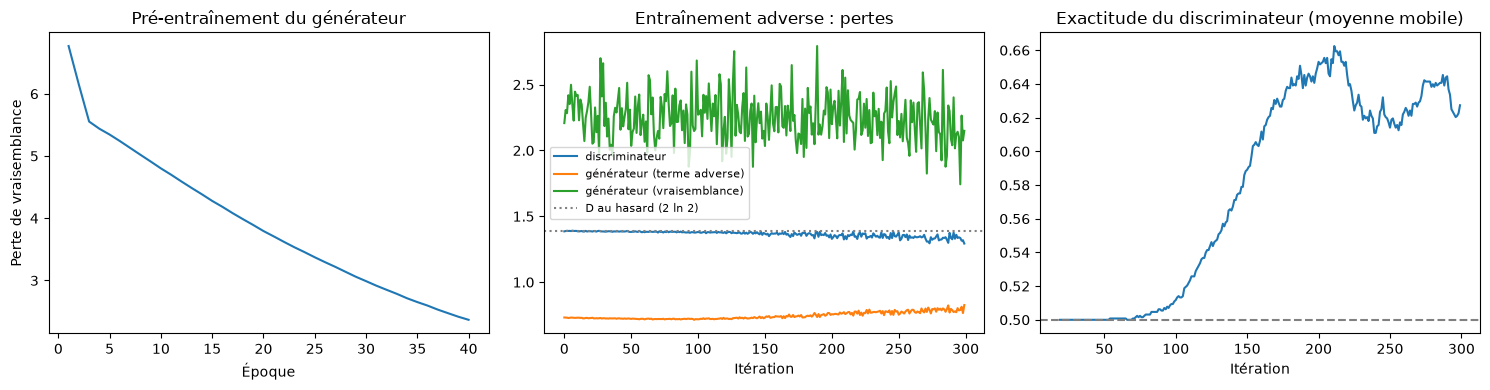

In [16]:
# Étape 2 : entraînement adverse. Le discriminateur apprend à séparer vrais et faux ; le
# générateur apprend à le tromper, avec le terme de vraisemblance pour rester proche du langage.
journal_gan = entrainer_adverse(generateur, discriminateur, reels, iterations=300)
print(
    f"Repère : perte de D d'un discriminateur qui répond au hasard = 2 ln 2 = {2 * np.log(2):.3f}"
)

# Diagnostic des indices de FORME restants, sur 500 phrases fabriquées à la température finale :
# la queue après <fin> est masquée avant le discriminateur (mesurée ici avant masquage), mais une
# phrase sans aucun <fin> reste reconnaissable, puisque tous les vrais spams en ont un.
part_avec_fin, part_occupee_apres_fin = forme_phrases(generateur)
print(f"Phrases fabriquées contenant <fin> : {part_avec_fin:.1%} (vrais spams : 100 %)")
print(
    f"Positions après <fin> occupées par un mot (avant masquage) : {part_occupee_apres_fin:.1%} "
    "(vrais spams : 0 %)"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(range(1, len(pertes_mle) + 1), pertes_mle)
axes[0].set_title("Pré-entraînement du générateur")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Perte de vraisemblance")
axes[1].plot(journal_gan["perte_d"], label="discriminateur")
axes[1].plot(journal_gan["perte_g_adverse"], label="générateur (terme adverse)")
axes[1].plot(journal_gan["perte_g_mv"], label="générateur (vraisemblance)")
axes[1].axhline(2 * np.log(2), color="gray", linestyle=":", label="D au hasard (2 ln 2)")
axes[1].set_title("Entraînement adverse : pertes")
axes[1].set_xlabel("Itération")
axes[1].legend(fontsize=8)
axes[2].plot(pd.Series(journal_gan["precision_d"]).rolling(20).mean())
axes[2].axhline(0.5, color="gray", linestyle="--")
axes[2].set_title("Exactitude du discriminateur (moyenne mobile)")
axes[2].set_xlabel("Itération")
plt.tight_layout()
plt.show()

> **Interprétation** : le pré-entraînement fait baisser la perte de vraisemblance du
> générateur d'environ 6,8 à 2,4 en 40 époques. Pendant les quatre-vingts premières itérations
> adverses, la perte du discriminateur reste à 2 ln 2 ≈ 1,386 et son exactitude à 50 % : il
> n'a encore rien appris (ce n'est pas qu'il « confond » le vrai et le faux). Son exactitude
> monte ensuite jusqu'à environ 0,66 (moyenne mobile), puis se stabilise vers 0,62 à 0,64, et
> sa perte finit à 1,29. **Indices de forme** : sans masquage, le discriminateur reconnaîtrait
> un faux à sa queue de séquence, puisque 100 % des positions qui suivent `<fin>` portent un mot
> dans les phrases fabriquées, contre 0 % dans les vrais spams (diagnostic affiché) : d'où le
> masquage. Un indice demeure : 22 % des phrases fabriquées n'émettent aucun `<fin>`, alors que
> tous les vrais spams en ont un. L'exactitude modeste du discriminateur mêle donc ce reste de
> forme et une part de contenu. Le générateur, lui, ne progresse pas : son terme adverse
> remonte de 0,72 à 0,83 et sa vraisemblance oscille autour de 2,1 à 2,5. Le jeu adverse
> n'améliore pas visiblement le générateur, qui reste proche de son pré-entraînement :
> l'instabilité classique des GAN textuels, que le terme de vraisemblance empêche de dégénérer.

### 6.1 Qualité des SMS générés : des mesures, et des points de comparaison

Une mesure n'a de sens que comparée à une référence. On mesure donc les SMS générés **et**
trois corpus de comparaison :

- les **vrais spams de validation** (jamais vus par le générateur) : ce que l'on vise ;
- les mêmes, **mots mélangés** au hasard : bon vocabulaire, aucune structure ;
- un **tirage de mots indépendants** selon leur fréquence dans les spams d'apprentissage, à la
  même longueur que les SMS générés : le plus simple des « générateurs », sans réseau.

Mesures : **diversité** (*distinct-1* et *distinct-2* : part de mots et de paires de mots
différents, à effectif égal) ; **structure locale** (part des suites de quatre mots déjà
présentes dans les spams d'apprentissage) ; **copies exactes** d'un spam d'apprentissage ;
part classée « spam » par le TextCNN de la section 4.

In [17]:
torch.manual_seed(GRAINE)
generes = [p for p in generer(generateur, vocab_gan, 600) if len(p) >= 3][:500]
print(f"SMS générés retenus (au moins 3 mots) : {len(generes)}")
for phrase in generes[:10]:
    print(" -", " ".join(phrase))

spams_val = validation.loc[validation["cible"] == 1, "mots"].tolist()
textes_app = {" ".join(m) for m in spams_app}
quadri_app = quadrigrammes(spams_app)

# Corpus de comparaison (tirages reproductibles).
tirage = np.random.default_rng(GRAINE)
compteur_spam = compter_mots(spams_app)
tirage_independant = tirer_independamment(tirage, compteur_spam, [len(p) for p in generes])
spams_val_melanges = melanger(tirage, spams_val)


def part_classee_spam(phrases: Sequence[Sequence[str]]) -> float:
    """Part des phrases que le TextCNN de la section 4 classe « spam » (seuil 0,5)."""
    sequences = torch.tensor([codeur.encoder(p) for p in phrases])
    return float(np.mean(probabilites(cnn, sequences) >= 0.5))


def qualite_de(phrases: Sequence[Sequence[str]]) -> dict[str, float]:
    """Mesures de qualité d'un corpus, à effectif comparable aux vrais spams de validation."""
    return mesurer(
        phrases,
        nb_comparables=len(spams_val),
        quadri_app=quadri_app,
        textes_app=textes_app,
        part_spam=part_classee_spam,
    )


qualite = pd.DataFrame(
    {
        "SMS générés (GAN)": qualite_de(generes),
        "vrais spams de validation": qualite_de(spams_val),
        "vrais spams, mots mélangés": qualite_de(spams_val_melanges),
        "mots tirés indépendamment": qualite_de(tirage_independant),
    }
).T
qualite.round(3)

SMS générés retenus (au moins 3 mots) : 500
 - great want chart entered 2nite chat going <nombre> in lookatme <nombre> <nombre> cash <nombre> only <argent> wk <argent> reply
 - <tel> chat <tel> now only <argent> msg <nombre> txt play inc draw go to any name and then join voda
 - hi balance between u have a <argent> prize guaranteed even great <nombre> chance <nombre> win been call <tel> now claim
 - please with the euro2004 no <nombre> for the official unsubscribe calls game love with offer sms call <tel> to see stop
 - for sunshine xmas to you <nombre> month join charged <argent> of joined ipod if u in all t del from
 - free our ringtone into yr weekend time address fantasy waiting for you chance to some chat now club to get call <tel> now <argent> national
 - get laid yo a c with b in and final high wk poly plus free love a
 - <tel> from landline a <argent> there with class a prize male you <nombre> <nombre> claim is <nombre> call <tel> txtauction with
 - free double waiting for call

,messages,distinct-1,distinct-2,4-grammes déjà vus dans les spams d'app.,copies exactes d'un spam d'app.,classés spam par le TextCNN
SMS générés (GAN),500.0,0.259,0.798,0.055,0.0,0.938
vrais spams de validation,94.0,0.285,0.650,0.206,0.0,0.936
"vrais spams, mots mélangés",94.0,0.285,0.922,0.001,0.0,0.915
mots tirés indépendamment,500.0,0.338,0.946,0.000,0.0,0.894


> **Interprétation** : (1) **Lecture** : les SMS générés enchaînent des mots-clés de spam
> (« call <tel> now », « <argent> prize guaranteed », « claim », « free ») sans grammaire :
> ce sont des caricatures de spam plus que des imitations. (2) **Part classée spam par le
> TextCNN** : 93,8 %, autant que les vrais spams (93,6 %), mais les mots mélangés au hasard
> (91,5 %) et les mots tirés indépendamment (89,4 %) font presque aussi bien : cette mesure dit
> seulement que le bon vocabulaire est présent, pas que le texte est réaliste. (3) **Structure
> locale** : 5,5 % des suites de quatre mots générées existent dans les spams d'apprentissage,
> contre 20,6 % pour de vrais spams jamais vus et 0 à 0,1 % pour les corpus sans ordre : le
> générateur a appris un début de structure locale, très loin du réel. (4) **Diversité** :
> distinct-1 de 0,259 contre 0,285 pour les vrais spams (il réutilise les mots fréquents) ;
> distinct-2 de 0,798, entre le réel (0,650) et le hasard (0,92 à 0,95) : il enchaîne des
> paires de mots que la langue n'associe pas. (5) **Aucune copie** d'un spam d'apprentissage.
> Bilan : le générateur reproduit le vocabulaire du spam et un peu de sa structure, pas des
> messages crédibles.

### 6.2 et 6.3 Utilité des SMS générés, et effet de l'augmentation : plusieurs graines

Ajouter des SMS générés à l'apprentissage améliore-t-il le détecteur ? Et l'augmentation de la
section 2.4 sert-elle ? Un seul entraînement ne suffit pas à le dire : le F1 de validation varie
d'une graine à l'autre (ordre des lots, initialisation), et ses 94 spams font qu'un message
change le F1 d'environ 0,01. On entraîne donc le TextCNN avec **cinq graines** pour chaque
variante, et on compare les moyennes **sur la validation** (le test reste réservé à
l'évaluation finale) :

1. référence : TextCNN avec augmentation (section 4) ;
2. sans augmentation ;
3. avec 300 SMS générés ajoutés, étiquetés spam ;
4. **témoin** : avec 300 vrais spams d'apprentissage tirés au hasard (avec remise) ajoutés. Il
   isole l'effet « plus de spams dans les lots » de l'effet « textes nouveaux ».

Remarque : les variantes 3 et 4 ajoutent des spams sans recalculer le poids $w$ de la perte ;
elles compensent donc un peu plus le déséquilibre que la référence, et c'est précisément ce que
le témoin neutralise.

In [18]:
x_gen = torch.tensor([codeur.encoder(p) for p in generes[:300]])
spams_reels = x_app[y_app == 1]
GRAINES_ETUDE = [1, 2, 3, 4, 5]


def jeu_variante(variante: str, graine: int) -> tuple[torch.Tensor, torch.Tensor, bool]:
    """Données d'apprentissage et usage de l'augmentation pour une variante et une graine."""
    if variante == "référence (augmentation)":
        return x_app, y_app, True
    if variante == "sans augmentation":
        return x_app, y_app, False
    if variante == "+ 300 SMS générés":
        ajout = x_gen
    else:  # témoin : 300 vrais spams tirés avec remise, tirage propre à la graine
        tirage_graine = torch.Generator().manual_seed(graine)
        ajout = spams_reels[torch.randint(len(spams_reels), (300,), generator=tirage_graine)]
    return torch.cat([x_app, ajout]), torch.cat([y_app, torch.ones(len(ajout))]), True


variantes = [
    "référence (augmentation)",
    "sans augmentation",
    "+ 300 SMS générés",
    "+ 300 vrais spams (témoin)",
]
debut = time.perf_counter()
lignes_etude = []
for variante in variantes:
    for graine in GRAINES_ETUDE:
        x_v, y_v, avec_augmentation = jeu_variante(variante, graine)
        torch.manual_seed(graine)
        modele_v = TextCNN(len(codeur.vocabulaire))
        h = entrainer(
            modele_v,
            x_v,
            y_v,
            x_val,
            y_val,
            perte,
            augmenteur,
            augmentation=avec_augmentation,
            graine=graine,
            bavard=False,
        )
        lignes_etude.append(
            {
                "variante": variante,
                "graine": graine,
                "F1 validation (meilleure époque)": max(h["f1_val"]),
            }
        )
etude = pd.DataFrame(lignes_etude)
print(f"{len(etude)} entraînements en {time.perf_counter() - debut:.0f} s")
synthese_etude = etude.groupby("variante", sort=False)["F1 validation (meilleure époque)"].agg(
    ["mean", "std", "min", "max"]
)
moyennes = synthese_etude["mean"].to_numpy()
rang_reference = variantes.index("référence (augmentation)")
synthese_etude["écart à la référence"] = moyennes - moyennes[rang_reference]
print(etude.pivot(index="graine", columns="variante").round(3).to_string())
synthese_etude.round(3)

20 entraînements en 644 s
         F1 validation (meilleure époque)                                                                      
variante                + 300 SMS générés + 300 vrais spams (témoin) référence (augmentation) sans augmentation
graine                                                                                                         
1                                   0.926                      0.931                    0.932             0.927
2                                   0.935                      0.927                    0.941             0.930
3                                   0.921                      0.921                    0.911             0.915
4                                   0.916                      0.921                    0.926             0.925
5                                   0.935                      0.947                    0.935             0.936


,mean,std,min,max,écart à la référence
variante,,,,,
référence (augmentation),0.929,0.011,0.911,0.941,0.000
sans augmentation,0.927,0.008,0.915,0.936,-0.002
+ 300 SMS générés,0.927,0.009,0.916,0.935,-0.002
+ 300 vrais spams (témoin),0.929,0.011,0.921,0.947,0.000


In [19]:
# Modèle « TextCNN + SMS générés » entraîné avec la graine principale, pour figurer dans
# l'évaluation finale de la section 7 aux côtés des autres candidats.
x_aug = torch.cat([x_app, x_gen])
y_aug = torch.cat([y_app, torch.ones(len(x_gen))])
torch.manual_seed(GRAINE)
cnn_gan = TextCNN(len(codeur.vocabulaire))
historique_cnn_gan = entrainer(
    cnn_gan,
    x_aug,
    y_aug,
    x_val,
    y_val,
    perte,
    augmenteur,
    graine=GRAINE,
    nom="TextCNN+GAN",
    bavard=False,
)
print(
    f"TextCNN + 300 SMS générés, graine {GRAINE} : "
    f"F1 validation {max(historique_cnn_gan['f1_val']):.3f}"
)

TextCNN + 300 SMS générés, graine 42 : F1 validation 0.916


> **Interprétation** : sur cinq graines, les quatre variantes ont le même F1 de validation
> moyen à 0,002 près (0,927 à 0,929), alors que l'écart-type d'une graine à l'autre est de
> 0,008 à 0,011 et que la référence seule va de 0,911 à 0,941 selon la graine. Conclusion :
> **ni l'augmentation, ni les 300 SMS générés, ni le témoin n'ont d'effet démontré** sur ce
> TextCNN ; les écarts entre variantes sont bien inférieurs au bruit de l'entraînement. Le gain
> apparent d'un seul entraînement ne prouverait donc rien : il faut comparer plusieurs graines.
> Avec la graine principale (42), le TextCNN + SMS générés obtient 0,916 de F1 de validation au
> seuil 0,5, contre 0,926 pour le TextCNN de référence : dans le bruit, lui aussi.

## 7. Évaluation finale et généralisation (C4.5)

**Méthode** : pour chaque modèle, le **seuil de décision** (probabilité au-delà de laquelle on
déclare un spam) est choisi sur la **validation**, en maximisant le F1 ; le **modèle retenu**
est celui qui a le meilleur F1 de validation. Puis chaque modèle est évalué **une seule fois**
sur le **test**, jamais vu : c'est la mesure de généralisation. Les indicateurs retenus sont
adaptés à des classes déséquilibrées : **précision** (part des alertes justifiées : un faux
positif bloque un vrai message), **rappel** (part des spams interceptés), **F1** (moyenne
harmonique des deux), **ROC-AUC** et **PR-AUC** (qualité du classement, quel que soit le seuil ;
la PR-AUC est la plus exigeante quand la classe positive est rare). L'exactitude seule serait
trompeuse : un modèle qui ne détecte aucun spam a déjà 87 % d'exactitude.

**Incertitude** : le test ne compte qu'environ 93 spams ; un spam de plus ou de moins déplace le
F1 d'environ 0,01. On donne donc pour chaque F1 un **intervalle de confiance à 95 % par
rééchantillonnage** (*bootstrap* : 2 000 tirages avec remise des messages de test, les mêmes
pour tous les modèles), et l'on compare le modèle retenu aux autres par le **test exact de
McNemar** (porte sur les messages où les deux modèles ne se trompent pas de la même façon).

In [20]:
# Les fonctions du seuil, du bootstrap et des indicateurs sont dans att_spam/evaluation.py.
probas: dict[str, tuple[Reels, Reels]] = {
    "TF-IDF + régression logistique (référence)": (
        proba_ref_val,
        probabilites_reference(vectoriseur, reference, test["mots"]),
    ),
    "TextCNN": (probabilites(cnn, x_val), probabilites(cnn, x_test)),
    "BiGRU": (probabilites(gru, x_val), probabilites(gru, x_test)),
    "TextCNN + SMS générés (GAN)": (probabilites(cnn_gan, x_val), probabilites(cnn_gan, x_test)),
    "DistilBERT (transfer learning)": (
        probabilites_bert(distilbert, bert_val),
        probabilites_bert(distilbert, bert_test),
    ),
}
y_val_np, y_test_np = y_val.numpy(), y_test.numpy()
tirages = tirages_bootstrap(GRAINE, len(y_test_np))
evaluations = {
    nom: evaluer(nom, y_val_np, p_val, y_test_np, p_test, tirages)
    for nom, (p_val, p_test) in probas.items()
}
seuils = {nom: evaluation.seuil for nom, evaluation in evaluations.items()}
predictions = {nom: evaluation.predictions for nom, evaluation in evaluations.items()}
matrices = {nom: evaluation.matrice for nom, evaluation in evaluations.items()}
resultats = pd.DataFrame([evaluation.ligne for evaluation in evaluations.values()]).set_index(
    "modèle"
)
# Le modèle retenu est choisi sur la VALIDATION, comme annoncé : le test ne sert qu'à mesurer.
retenu = str(resultats["F1 validation"].idxmax())
print("Modèle retenu (meilleur F1 de validation) :", retenu)
resultats

Modèle retenu (meilleur F1 de validation) : DistilBERT (transfer learning)


,seuil (validation),F1 validation,précision test,rappel test,F1 test,F1 test IC 95 %,erreurs test,ROC-AUC test,PR-AUC test
modèle,,,,,,,,,
TF-IDF + régression logistique (référence),0.44,0.958,0.957,0.968,0.963,[0.931 ; 0.988],7,0.9895,0.9815
TextCNN,0.46,0.926,0.900,0.968,0.933,[0.892 ; 0.966],13,0.9836,0.9744
BiGRU,0.73,0.952,0.989,0.946,0.967,[0.938 ; 0.990],6,0.9921,0.9824
TextCNN + SMS générés (GAN),0.74,0.924,0.957,0.946,0.951,[0.914 ; 0.980],9,0.9848,0.9753
DistilBERT (transfer learning),0.91,0.989,0.989,0.989,0.989,[0.971 ; 1.000],2,0.9996,0.9978


DistilBERT contre TF-IDF + régression logistique : 6 messages où seul le retenu a raison, 1 où seul l'autre a raison, p = 0.125
DistilBERT contre TextCNN                      : 12 messages où seul le retenu a raison, 1 où seul l'autre a raison, p = 0.003
DistilBERT contre BiGRU                        : 5 messages où seul le retenu a raison, 1 où seul l'autre a raison, p = 0.219
DistilBERT contre TextCNN + SMS générés        : 8 messages où seul le retenu a raison, 1 où seul l'autre a raison, p = 0.039


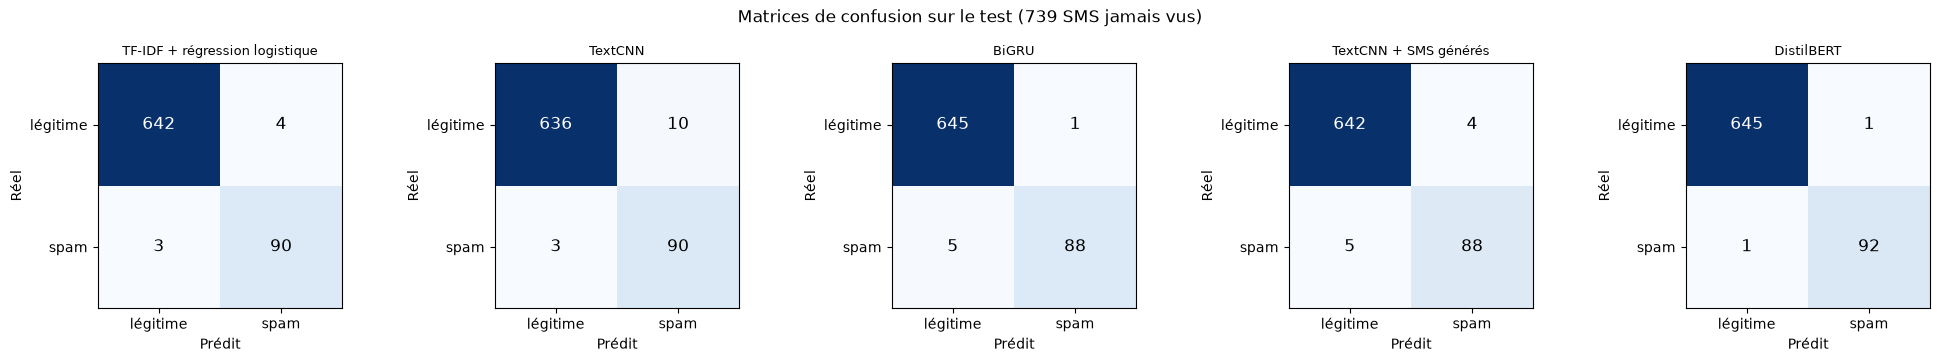

Rappel 92/93 = 0.989, IC 95 % [0.942 ; 0.998]
Précision 92/93 = 0.989, IC 95 % [0.942 ; 0.998]
Messages légitimes bloqués à tort : 1 sur 646
TextCNN    : F1 apprentissage 0.994 ; validation 0.926 ; écart +0.067
BiGRU      : F1 apprentissage 0.986 ; validation 0.948 ; écart +0.038
DistilBERT : F1 apprentissage 0.987 ; validation 0.968 ; écart +0.019


In [21]:
# Le modèle retenu est-il significativement meilleur que les autres ? Test exact de McNemar :
# parmi les messages où un seul des deux modèles se trompe, la répartition doit être 50/50 si
# les deux modèles se valent.
juste_retenu = predictions[retenu] == y_test_np
for nom in probas:
    if nom == retenu:
        continue
    seul_retenu_juste, seul_autre_juste, p_mcnemar = mcnemar(
        juste_retenu, predictions[nom] == y_test_np
    )
    print(
        f"{retenu.split(' (')[0]} contre {nom.split(' (')[0]:<28} : {seul_retenu_juste} messages "
        f"où seul le retenu a raison, {seul_autre_juste} où seul l'autre a raison, "
        f"p = {p_mcnemar:.3f}"
    )

fig, axes = plt.subplots(1, len(matrices), figsize=(4 * len(matrices), 3.6))
for ax, (nom, matrice) in zip(axes, matrices.items(), strict=True):
    ax.imshow(matrice, cmap="Blues")
    for (i, j), valeur in np.ndenumerate(matrice):
        couleur_texte = "white" if valeur > matrice.max() / 2 else "black"  # contraste
        ax.text(j, i, valeur, ha="center", va="center", fontsize=12, color=couleur_texte)
    ax.set_xticks([0, 1], ["légitime", "spam"])
    ax.set_yticks([0, 1], ["légitime", "spam"])
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.set_title(nom.split(" (")[0], fontsize=9)
fig.suptitle(f"Matrices de confusion sur le test ({len(test)} SMS jamais vus)")
plt.tight_layout()
plt.show()

# Performance du modèle retenu, avec intervalles de Wilson pour le rappel et la précision.
bilan = performance(y_test_np, predictions[retenu])
print(
    f"Rappel {bilan.vrais_positifs}/{bilan.nb_spams} = "
    f"{bilan.vrais_positifs / bilan.nb_spams:.3f}, "
    f"IC 95 % [{bilan.ic_rappel[0]:.3f} ; {bilan.ic_rappel[1]:.3f}]"
)
print(
    f"Précision {bilan.vrais_positifs}/{bilan.nb_alertes} = "
    f"{bilan.vrais_positifs / bilan.nb_alertes:.3f}, "
    f"IC 95 % [{bilan.ic_precision[0]:.3f} ; {bilan.ic_precision[1]:.3f}]"
)
print(f"Messages légitimes bloqués à tort : {bilan.faux_positifs} sur {bilan.nb_legitimes}")

# Test de sur-apprentissage : écart entre le F1 d'apprentissage et de validation à la meilleure
# époque de chaque réseau.
for nom, h in [
    ("TextCNN", historique_cnn),
    ("BiGRU", historique_gru),
    ("DistilBERT", historique_bert),
]:
    k = meilleure_epoque(h)
    print(
        f"{nom:<10} : F1 apprentissage {h['f1_app'][k]:.3f} ; validation {h['f1_val'][k]:.3f} "
        f"; écart {h['f1_app'][k] - h['f1_val'][k]:+.3f}"
    )

In [22]:
# Deux contrôles de robustesse du chiffre annoncé (lecture seule : le seuil et le modèle
# retenus restent ceux choisis sur la validation).
# 1. Sensibilité au seuil : F1 du modèle retenu pour quelques seuils autour de celui choisi.
p_val_retenu, p_test_retenu = probas[retenu]
print(f"Sensibilité au seuil - {retenu} (seuil retenu sur la validation : {seuils[retenu]:.2f})")
for seuil_essai in sorted({0.5, round(seuils[retenu] - 0.1, 2), seuils[retenu], 0.95}):
    print(
        f"  seuil {seuil_essai:.2f} : F1 validation "
        f"{f1(y_val_np, p_val_retenu >= seuil_essai):.3f} ; F1 test "
        f"{f1(y_test_np, p_test_retenu >= seuil_essai):.3f} ; erreurs test "
        f"{int(((p_test_retenu >= seuil_essai) != y_test_np).sum())}"
    )

# 2. Variabilité d'un pli à l'autre : le test n'est qu'UN des 7 plis groupés. On réentraîne la
# référence TF-IDF (rapide) en prenant tour à tour chaque pli comme test, les 6 autres pour
# l'apprentissage, au seuil 0,5 : la dispersion dit combien le chiffre dépend du pli tiré.
# (DistilBERT, à 9 minutes par ajustement, n'est pas refait sur les 7 plis.)
f1_par_pli = f1_reference_par_pli(donnees, plis, GRAINE)
for numero_pli, f1_pli in enumerate(f1_par_pli):
    role = " (pli de test du notebook)" if numero_pli == 0 else ""
    print(f"  TF-IDF, pli {numero_pli} pris comme test : F1 {f1_pli:.3f}{role}")
print(
    f"TF-IDF sur les 7 plis : F1 moyen {np.mean(f1_par_pli):.3f}, écart-type "
    f"{np.std(f1_par_pli, ddof=1):.3f}, de {min(f1_par_pli):.3f} à {max(f1_par_pli):.3f}"
)

Sensibilité au seuil - DistilBERT (transfer learning) (seuil retenu sur la validation : 0.91)
  seuil 0.50 : F1 validation 0.968 ; F1 test 0.979 ; erreurs test 4
  seuil 0.81 : F1 validation 0.984 ; F1 test 0.984 ; erreurs test 3
  seuil 0.91 : F1 validation 0.989 ; F1 test 0.989 ; erreurs test 2
  seuil 0.95 : F1 validation 0.978 ; F1 test 0.989 ; erreurs test 2


  TF-IDF, pli 0 pris comme test : F1 0.973 (pli de test du notebook)
  TF-IDF, pli 1 pris comme test : F1 0.952
  TF-IDF, pli 2 pris comme test : F1 0.926
  TF-IDF, pli 3 pris comme test : F1 0.941
  TF-IDF, pli 4 pris comme test : F1 0.957
  TF-IDF, pli 5 pris comme test : F1 0.963
  TF-IDF, pli 6 pris comme test : F1 0.942
TF-IDF sur les 7 plis : F1 moyen 0.950, écart-type 0.016, de 0.926 à 0.973


> **Performance atteinte** : le détecteur retenu sur la validation, **DistilBERT ajusté**, au seuil de
> 0,91 choisi sur cette validation,
> intercepte **92 spams sur 93** sur le test (rappel 0,989, intervalle de confiance à 95 % de
> 0,94 à 1,00) et ne bloque à tort qu'**un message légitime sur 646** (précision 0,989, de 0,94
> à 1,00), soit un **F1 de 0,989** (de 0,971 à 1,000) et une PR-AUC de 0,998, sur 739 SMS
> jamais vus, sans quasi-doublon (similarité ≥ 0,8) d'un SMS d'apprentissage.
>
> **Robustesse de ce chiffre** : (1) il est en haut de la fourchette du seuil : au seuil 0,5, le
> même modèle fait 0,979 (4 erreurs), au seuil 0,81, 0,984 (3 erreurs) ; le seuil 0,91 a été
> choisi sur la validation, comme prévu, mais c'est un maximum étroit ; (2) le pli de test est
> favorable : la référence TF-IDF, réentraînée en prenant tour à tour chacun des 7 plis comme
> test, va de 0,926 à 0,973 (moyenne 0,950, écart-type 0,016), et le pli de test du notebook
> donne le meilleur score des sept. Tous les scores de test ci-dessus sont donc probablement
> optimistes d'environ 0,02 : **une performance attendue autour de 0,96 à 0,98 de F1** pour
> DistilBERT est une lecture plus prudente.
>
> **Analyse** : la référence TF-IDF + régression logistique est très solide (F1 de test 0,963,
> 7 erreurs) ; le BiGRU (0,967, 6 erreurs) et le TextCNN + SMS générés (0,951, 9 erreurs) font
> à peu près jeu égal avec elle ; le TextCNN seul, **avec la graine 42**, est en retrait (0,933,
> 13 erreurs), mais son F1 de validation varie de 0,911 à 0,941 selon la graine (section 6.3) :
> ce retrait dépend de la graine. Sur des textes courts aux signaux lexicaux très marqués, 3 700
> exemples ne suffisent pas à un réseau entraîné de zéro pour dépasser nettement un bon modèle
> linéaire. DistilBERT fait le moins d'erreurs (2), grâce à la connaissance de l'anglais apprise
> ailleurs. Mais son avance n'est pas significative contre la référence TF-IDF (McNemar,
> p = 0,13) ni contre le BiGRU (p = 0,22) ; elle l'est contre le TextCNN seul (p = 0,003, sous
> le seuil de Bonferroni de 0,0125 pour ces quatre comparaisons) ; contre le TextCNN + SMS
> générés, p = 0,04 ne passe pas ce seuil. Et ces comparaisons aux TextCNN ne valent que pour la
> graine 42.
>
> **Généralisation** : le F1 de DistilBERT est de 0,989 en validation comme en test, au seuil de 0,91 ;
> les écarts entre apprentissage et validation sont faibles pour DistilBERT (0,019) et modérés pour le
> BiGRU (0,038) et le TextCNN (0,067). Le découpage par groupes écarte les quasi-doublons communs à
> l'apprentissage et au test (aucun groupe partagé ; similarité maximale de 0,786, sous le seuil de
> 0,8), ce qu'un découpage au hasard ne garantit pas. Le notebook ne compare pas les deux découpages :
> il ne démontre donc pas que le découpage par groupes donne un F1 plus bas, et sur un test de 93
> spams le F1 de la référence TF-IDF varie déjà de 0,926 à 0,973 d'un pli à l'autre. Reste le décalage
> de domaine (section 11).

## 8. Signaux détectés : sur quoi les modèles s'appuient-ils ?

Deux lectures complémentaires : (1) les **coefficients du modèle linéaire de référence**
(TF-IDF), directement lisibles ; (2) pour le **modèle retenu**, une **ablation** : on retire un
signal (un jeton ou un mot) des spams de test qu'il détecte, et l'on mesure de combien baisse
leur probabilité de spam, et combien repassent sous le seuil.

In [23]:
# (1) Les mots qui poussent le plus vers « spam » ou « légitime » dans le modèle LINÉAIRE.
noms_variables = np.array(vectoriseur.get_feature_names_out())
coefficients = reference.coef_[0]
ordre = np.argsort(coefficients)
print(
    "Modèle linéaire de référence - vers SPAM     :", ", ".join(noms_variables[ordre[-15:]][::-1])
)
print("Modèle linéaire de référence - vers LÉGITIME :", ", ".join(noms_variables[ordre[:15]]))

Modèle linéaire de référence - vers SPAM     : <tel>, <argent>, <url>, <nombre>, free, text, your, reply, txt, mobile, call, to, service, for, ringtone
Modèle linéaire de référence - vers LÉGITIME : i, me, my, gt, lt, ok, come, its, at, i'm, then, it, that, going, k


In [24]:
# (2) Ablation sur le modèle retenu. Chaque modèle sait noter une liste de textes normalisés.
def probas_textes(nom: str, textes: Sequence[str]) -> Reels:
    """Probabilités de spam d'un modèle pour des textes déjà normalisés (section 2.1)."""
    if nom.startswith("TF-IDF"):
        return probabilites_reference(vectoriseur, reference, [decouper_mots(t) for t in textes])
    if nom.startswith("DistilBERT"):
        return probabilites_bert(
            distilbert, encoder_bert(tokeniseur, list(textes), np.zeros(len(textes)))
        )
    reseau = {"TextCNN": cnn, "BiGRU": gru, "TextCNN + SMS générés (GAN)": cnn_gan}[nom]
    return probabilites(
        reseau, torch.tensor([codeur.encoder(decouper_mots(t)) for t in textes])
    )


spams_detectes = test.loc[(test["cible"] == 1) & predictions[retenu], "texte_normalise"].tolist()
lignes_ablation = ablation(
    spams_detectes,
    lambda textes: probas_textes(retenu, textes),
    seuils[retenu],
    ["<tel>", "<argent>", "<url>", "<nombre>", "free", "call", "txt", "claim", "prize"],
)
print(f"Ablation sur « {retenu} » ({len(spams_detectes)} spams de test détectés)")
pd.DataFrame(lignes_ablation).round(3)

Ablation sur « DistilBERT (transfer learning) » (92 spams de test détectés)


,signal retiré,spams détectés qui le contiennent,baisse moyenne de probabilité,repassent sous le seuil
0,<tel>,75,0.027,4
1,<argent>,46,0.021,1
2,<url>,4,0.000,0
3,<nombre>,67,0.002,0
4,free,21,0.000,0
5,call,49,0.000,0
6,txt,21,0.018,1
7,claim,9,0.000,0
8,prize,3,-0.000,0


In [25]:
# Erreurs du modèle retenu sur le test.
faux_positifs, faux_negatifs = erreurs_du_modele(test, probas[retenu][1], seuils[retenu])
print(
    f"{retenu} (seuil {seuils[retenu]:.2f}) : {len(faux_positifs)} faux positifs, "
    f"{len(faux_negatifs)} faux négatifs"
)
for titre, cas in [
    ("FAUX POSITIFS (légitimes pris pour du spam)", faux_positifs),
    ("FAUX NÉGATIFS (spams non détectés)", faux_negatifs),
]:
    print(f"\n{titre}")
    for _, ligne in cas.head(6).iterrows():
        print(f" [{ligne['proba']:.2f}] {ligne['texte'][:150]}")

DistilBERT (transfer learning) (seuil 0.91) : 1 faux positifs, 1 faux négatifs

FAUX POSITIFS (légitimes pris pour du spam)
 [0.99] <SMS du corpus, non reproduit>

FAUX NÉGATIFS (spams non détectés)
 [0.01] <SMS du corpus, non reproduit>


> **Interprétation** : dans le **modèle linéaire de référence**, les signaux de spam les plus
> forts sont les jetons créés à la normalisation (`<tel>`, `<argent>`, `<url>`, `<nombre>`),
> puis des mots d'appel à l'action ou de service (« free », « text », « reply », « txt »,
> « call », « mobile », « service », « ringtone ») ; les messages légitimes se reconnaissent à
> la première personne (« i », « me », « my », « i'm ») et au registre familier (« ok »,
> « come », « going », « k »). (« lt » et « gt » viennent du code `&lt;#&gt;` présent dans des
> messages légitimes du corpus : un artefact du jeu de données.) L'**ablation sur DistilBERT**
> montre un modèle qui ne dépend d'aucun signal isolé : retirer `<tel>` ne fait repasser sous
> le seuil que 4 des 75 spams détectés qui en contiennent (baisse moyenne de probabilité 0,03),
> `<argent>` et « txt » un seul chacun, les autres aucun : il combine de nombreux indices
> redondants. Ses deux erreurs : un faux positif très court et ambigu (un message de quatre mots,
> probabilité 0,99) et un faux négatif écrit sur un ton personnel, qui imite un
> message d'ami (probabilité 0,01). Pistes : ajouter des métadonnées (expéditeur, fréquence
> d'envoi) et fixer le seuil selon le coût métier d'un faux positif comparé à un faux
> négatif.

## 9. Lien avec le thème du référentiel : l'analyse de sentiment

Le référentiel du bloc 4 illustre la compétence par l'**analyse de sentiment** (déterminer
l'opinion d'un utilisateur sur un produit). La détection de spam est le même problème
technique : un texte court, transformé en tenseur, classé par un réseau en deux catégories. La
chaîne construite ici s'y transpose directement :

| Étape | Détection de spam (ce projet) | Analyse de sentiment |
|---|---|---|
| Données | SMS étiquetés spam / légitime | avis clients étiquetés positif / négatif (ou notés) |
| Préparation | normalisation, vocabulaire, séquences, augmentation | identique ; garder les négations (« not good ») |
| Réseaux | TextCNN, BiGRU, DistilBERT ajusté | identiques ; sortie à 3 classes ou plus si besoin |
| Coût | entropie croisée binaire pondérée | entropie croisée catégorielle |
| Données créées (GAN) | spams synthétiques | avis synthétiques de la classe rare |

Seuls changent les étiquettes et, pour plus de deux classes, la dernière couche et la perte.

## 10. Conformité RGPD

- **Nature des données** : les SMS sont des **communications privées** (secret des
  correspondances ; directive ePrivacy 2002/58/CE). Le jeu utilisé est un corpus public de
  recherche, déjà diffusé à cette fin.
- **Minimisation** : pour **tous** les modèles, DistilBERT compris, la plupart des numéros de
  téléphone, des liens et des montants sont remplacés par des jetons (`<tel>`, `<url>`,
  `<argent>`) avant tout apprentissage (section 2.1) ; le vocabulaire des réseaux construits
  ignore les mots vus une seule fois (qui pourraient être des noms propres) ; les SMS générés
  par le GAN sont composés de mots vus au moins deux fois dans les spams et ne contiennent aucun
  lien ; ils peuvent reprendre des codes de service répétés par les spammeurs (par exemple une
  boîte postale), qui ne désignent pas une personne. Limites : un numéro collé à un mot échappe
  à la règle des cinq chiffres et reste dans le texte (« 08452810075over18's », sortie de la
  section 2.1) ; deux numéros surtaxés de ce type, répétés dans les spams d'apprentissage,
  entrent ainsi dans le vocabulaire du GAN (`call09050000327`, `tscs087147403231winawk`) ;
  DistilBERT, qui découpe les mots en sous-mots, voit encore les prénoms ou surnoms du texte.
- **En production chez AT&T** : base légale à établir (obligation de sécurité du réseau,
  intérêt légitime de protection des abonnés contre la fraude), information des abonnés, analyse
  automatisée **sans lecture humaine** des messages, durée de conservation courte des SMS servant
  au réentraînement, droit d'opposition, et un recours en cas de message légitime bloqué
  (le faux positif a un coût pour l'abonné ; il est mesuré par la précision).
- **Modèles publiés** : un réseau entraîné peut mémoriser des fragments de ses données ; on ne
  publie que des modèles entraînés sur des données minimisées.

## 11. Limites

- **Décalage de domaine** : le corpus est britannique et date des années 2000 ; le spam reçu
  aujourd'hui par les abonnés américains d'AT&T (liens raccourcis, faux colis, faux codes
  bancaires) est différent. Avant tout déploiement, il faudrait réévaluer le modèle sur des SMS
  récents d'AT&T, puis le réentraîner régulièrement.
- **Petit test** : environ 93 spams de test ; les intervalles de confiance de la section 7 se
  chevauchent largement, et les écarts entre les meilleurs modèles ne sont pas significatifs.
- **Une graine** pour les modèles de la section 7 (cinq graines seulement pour l'étude du
  TextCNN en 6.3) : un classement entre modèles proches peut changer d'une graine à l'autre.
- **Seuil** choisi pour maximiser le F1 sur la validation ; en production, il se fixe selon le
  coût métier d'un message légitime bloqué comparé à un spam qui passe.
- **Le contenu seul**, comme l'exige l'énoncé : l'expéditeur, la fréquence d'envoi ou les
  signalements des abonnés amélioreraient nettement la détection.
- **Générateur adverse** : ses SMS ne sont pas grammaticaux et n'apportent pas de gain démontré
  (section 6) ; c'est une démonstration de la technique, pas un outil de production.

In [26]:
# 12. Sauvegarde des modèles et du vocabulaire (pour un usage ultérieur ou une API).
dossier = Path("modeles")
dossier.mkdir(exist_ok=True)
torch.save(cnn.state_dict(), dossier / "textcnn.pt")
torch.save(gru.state_dict(), dossier / "bigru.pt")
torch.save(
    {"vocabulaire": codeur.vocabulaire, "longueur": codeur.longueur}, dossier / "vocabulaire.pt"
)
# DistilBERT ajusté : poids (format safetensors) et tokeniseur, rechargeables par
# AutoModelForSequenceClassification.from_pretrained("modeles/distilbert_ajuste").
distilbert.save_pretrained(dossier / "distilbert_ajuste")
tokeniseur.save_pretrained(dossier / "distilbert_ajuste")
resultats.to_csv(dossier / "resultats_test.csv")
print("Fichiers sauvegardés :", sorted(f.name for f in dossier.iterdir()))

Fichiers sauvegardés : ['bigru.pt', 'distilbert_ajuste', 'resultats_test.csv', 'textcnn.pt', 'vocabulaire.pt']


*Copyright © 2026 · voir le fichier LICENSE du dépôt*